# 03 - Clustering

Segments `Mall_Customers.csv` using K-Means, Agglomerative Clustering, and DBSCAN on `Annual Income (k$)` and `Spending Score (1-100)`.

### What this notebook does

**Clustering** is an unsupervised machine learning task: there is no target
label to predict. Instead, the algorithm groups similar data points together
based on their feature values alone, so that points within a group are more
alike than points in different groups.

This notebook segments mall customers into groups based on their annual
income and spending score, using three different clustering algorithms
(K-Means, Agglomerative/Hierarchical Clustering, and DBSCAN), and reports
each one's results honestly — including DBSCAN's limitations on this
dataset — rather than assuming every algorithm finds good clusters.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Mall_Customers.csv to Mall_Customers.csv


In [ ]:
import os
import shutil

os.makedirs('/content/ML-Algo/data', exist_ok=True)

shutil.move(
    '/content/Mall_Customers.csv',
    '/content/ML-Algo/data/Mall_Customers.csv'
)

print("Mall Customers dataset added successfully!")

Mall Customers dataset added successfully!


In [ ]:
import os
import sys

repo_path = "/content/ML-Algo"

print("Folder exists:", os.path.exists(repo_path))
print("Contents:", os.listdir(repo_path) if os.path.exists(repo_path) else "Folder missing")

Folder exists: True
Contents: ['data']


In [ ]:
import os

for folder in ['/content', '/content/ML-Algo']:
    print(f'\n{folder}:')
    print(os.listdir(folder))


/content:
['.config', 'ML-Algo', 'sample_data']

/content/ML-Algo:
['data']


In [ ]:
import os
import pandas as pd

file_path = "/content/ML-Algo/data/Mall_Customers.csv"

print("Dataset exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    print(df.head())
    print(df.columns.tolist())

Dataset exists: True
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


Best K by silhouette score: 5

Clustering comparison:


,model,n_clusters,n_noise_points,silhouette_score
0,KMeans,5,0,0.5547
1,Agglomerative,5,0,0.5538
2,DBSCAN,7,35,0.5243



K-Means customer segment profiles:


,Annual Income (k$),Spending Score (1-100),Age,count
KMeans_cluster,,,,
0,55.3,49.5,42.7,81
1,86.5,82.1,32.7,39
2,25.7,79.4,25.3,22
3,88.2,17.1,41.1,35
4,26.3,20.9,45.2,23



First five customer assignments:


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),KMeans_cluster,Agglomerative_cluster,DBSCAN_cluster
0,1,Male,19,15,39,4,4,2
1,2,Male,21,15,81,2,3,0
2,3,Female,20,16,6,4,4,1
3,4,Female,23,16,77,2,3,0
4,5,Female,31,17,40,4,4,2


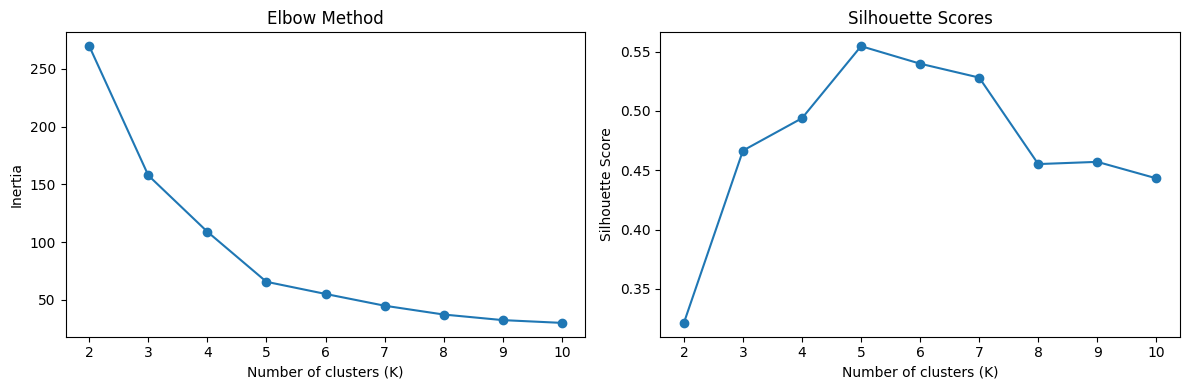

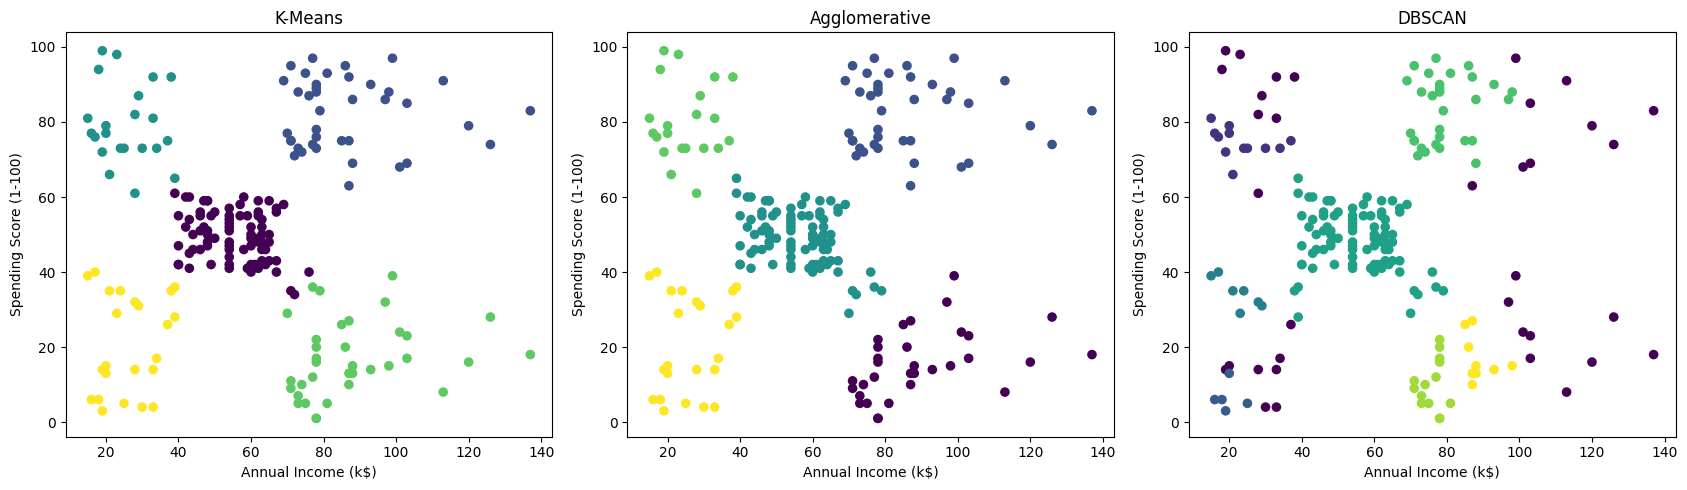

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

# Load dataset
file_path = "/content/ML-Algo/data/Mall_Customers.csv"
df = pd.read_csv(file_path)

# Select features
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features]

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# K-Means: find best K from 2 to 10
k_values = range(2, 11)
inertias = []
silhouettes = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

best_k = list(k_values)[np.argmax(silhouettes)]
print("Best K by silhouette score:", best_k)

# Fit all three algorithms
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["KMeans_cluster"] = kmeans.fit_predict(X_scaled)

agg = AgglomerativeClustering(n_clusters=best_k)
df["Agglomerative_cluster"] = agg.fit_predict(X_scaled)

# DBSCAN parameters
dbscan = DBSCAN(eps=0.3, min_samples=5)
df["DBSCAN_cluster"] = dbscan.fit_predict(X_scaled)

# Calculate metrics
results = []

for name, labels in [
    ("KMeans", df["KMeans_cluster"].values),
    ("Agglomerative", df["Agglomerative_cluster"].values),
    ("DBSCAN", df["DBSCAN_cluster"].values)
]:
    n_clusters = len(set(labels) - {-1})
    n_noise = int(np.sum(labels == -1))

    valid = labels != -1 if name == "DBSCAN" else np.ones(len(labels), dtype=bool)
    valid_labels = labels[valid]
    n_valid_clusters = len(set(valid_labels))

    score = (
        silhouette_score(X_scaled[valid], valid_labels)
        if n_valid_clusters >= 2 and n_valid_clusters < len(valid_labels)
        else np.nan
    )

    results.append({
        "model": name,
        "n_clusters": n_clusters,
        "n_noise_points": n_noise,
        "silhouette_score": score
    })

metrics_df = pd.DataFrame(results)
print("\nClustering comparison:")
display(metrics_df.round(4))

# Customer segment profiles
print("\nK-Means customer segment profiles:")
display(
    df.groupby("KMeans_cluster")[
        ["Annual Income (k$)", "Spending Score (1-100)", "Age"]
    ].mean().round(1).join(
        df.groupby("KMeans_cluster").size().rename("count")
    )
)

print("\nFirst five customer assignments:")
display(df.head())

# Elbow and silhouette graphs
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_values), silhouettes, marker="o")
axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

# Plot customer clusters
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, column) in zip(axes, [
    ("K-Means", "KMeans_cluster"),
    ("Agglomerative", "Agglomerative_cluster"),
    ("DBSCAN", "DBSCAN_cluster")
]):
    scatter = ax.scatter(
        X[features[0]], X[features[1]],
        c=df[column], cmap="viridis", s=35
    )
    ax.set_title(name)
    ax.set_xlabel(features[0])
    ax.set_ylabel(features[1])

plt.tight_layout()
plt.show()